In [1]:
import pandas as pd
import yfinance as yf
from datetime import timedelta

In [2]:
# Define the date range.

start_date = pd.to_datetime("2022-06-01")
end_date = pd.to_datetime("2023-01-05") - timedelta(days=1)

In [3]:
# Download stock data.
# yfinance excludes the end date, so add one day to include January 4.

stk_data = yf.download("TATACONSUM.NS", start=start_date, end=end_date + timedelta(days=1))
print(stk_data)

[*********************100%***********************]  1 of 1 completed

Price              Close          High           Low          Open  \
Ticker     TATACONSUM.NS TATACONSUM.NS TATACONSUM.NS TATACONSUM.NS   
Date                                                                 
2022-06-01    730.223511    748.836511    727.009438    729.168159   
2022-06-02    727.489136    729.647857    716.695528    726.289846   
2022-06-03    723.315613    739.721872    721.540629    729.168123   
2022-06-06    732.670105    738.762473    715.064497    726.050002   
2022-06-07    725.906006    731.086960    715.831973    731.086960   
...                  ...           ...           ...           ...   
2022-12-29    750.538452    753.342962    737.966618    753.342962   
2022-12-30    741.689880    756.534292    739.804093    752.375928   
2023-01-02    737.193054    745.606525    733.131373    744.542778   
2023-01-03    741.883301    742.608599    734.098387    739.804089   
2023-01-04    737.144653    742.221740    734.388544    742.221740   

Price             V

In [4]:
stk_data.columns = stk_data.columns.droplevel("Ticker")
stk_data.columns.name = None

stk_data.head()

,Close,High,Low,Open,Volume
Date,,,,,
2022-06-01,730.223511,748.836511,727.009438,729.168159,1641729
2022-06-02,727.489136,729.647857,716.695528,726.289846,630109
2022-06-03,723.315613,739.721872,721.540629,729.168123,1747685
2022-06-06,732.670105,738.762473,715.064497,726.050002,1441390
2022-06-07,725.906006,731.086960,715.831973,731.086960,1346609


In [5]:
# Keep only the price columns, excluding Volume.

price_columns = ["Open", "High", "Low", "Close"]
stk_data = stk_data[price_columns].copy()

In [6]:
stk_data.head()

,Open,High,Low,Close
Date,,,,
2022-06-01,729.168159,748.836511,727.009438,730.223511
2022-06-02,726.289846,729.647857,716.695528,727.489136
2022-06-03,729.168123,739.721872,721.540629,723.315613
2022-06-06,726.050002,738.762473,715.064497,732.670105
2022-06-07,731.086960,731.086960,715.831973,725.906006


In [7]:
# Create every calendar date in the requested range.
all_date = pd.date_range(start=start_date, end=end_date, freq="D")

In [8]:
# Expand the stock data to include all calendar dates.
# Weekends and market holidays will contain NaN values.
# reindex() sets the index automatically, avoiding the length mismatch.
dummyDate = stk_data.reindex(all_date)

In [9]:
# Give the date index a descriptive name.
dummyDate.index.name = "Date"

In [10]:
# Display the resulting data in a notebook.
dummyDate

,Open,High,Low,Close
Date,,,,
2022-06-01,729.168159,748.836511,727.009438,730.223511
2022-06-02,726.289846,729.647857,716.695528,727.489136
2022-06-03,729.168123,739.721872,721.540629,723.315613
2022-06-04,NaN,NaN,NaN,NaN
2022-06-05,NaN,NaN,NaN,NaN
...,...,...,...,...
2022-12-31,NaN,NaN,NaN,NaN
2023-01-01,NaN,NaN,NaN,NaN
2023-01-02,744.542778,745.606525,733.131373,737.193054


In [11]:
# Copy the data containing all calendar dates.
filled_data = dummyDate.copy()

In [12]:
# Get the previous available closing price for each date.
previous_close = filled_data["Close"].ffill()

In [13]:
# Fill missing price values with the previous closing price.
# This represents an unchanged price on days without trading.

price_columns = ["Open", "High", "Low", "Close"]
filled_data[price_columns] = filled_data[price_columns].fillna(previous_close, axis=0)

In [15]:
# Display the filled data.
filled_data

,Open,High,Low,Close
Date,,,,
2022-06-01,729.168159,748.836511,727.009438,730.223511
2022-06-02,726.289846,729.647857,716.695528,727.489136
2022-06-03,729.168123,739.721872,721.540629,723.315613
2022-06-04,NaN,NaN,NaN,NaN
2022-06-05,NaN,NaN,NaN,NaN
...,...,...,...,...
2022-12-31,NaN,NaN,NaN,NaN
2023-01-01,NaN,NaN,NaN,NaN
2023-01-02,744.542778,745.606525,733.131373,737.193054


In [16]:
# Copy the data containing all calendar dates.
filled_data = dummyDate.copy()

In [17]:
# Carry the last available closing price forward to missing dates.
previous_close = filled_data["Close"].ffill()

In [18]:
# Fill each price column using the previous close, matching by date.
for column in ["Open", "High", "Low", "Close"]:
    filled_data[column] = filled_data[column].fillna(previous_close)

In [19]:
# Check the number of missing values remaining in each column.
print(filled_data.isna().sum())

Open     0
High     0
Low      0
Close    0
dtype: int64


In [20]:
# Display the filled data.
filled_data

,Open,High,Low,Close
Date,,,,
2022-06-01,729.168159,748.836511,727.009438,730.223511
2022-06-02,726.289846,729.647857,716.695528,727.489136
2022-06-03,729.168123,739.721872,721.540629,723.315613
2022-06-04,723.315613,723.315613,723.315613,723.315613
2022-06-05,723.315613,723.315613,723.315613,723.315613
...,...,...,...,...
2022-12-31,741.689880,741.689880,741.689880,741.689880
2023-01-01,741.689880,741.689880,741.689880,741.689880
2023-01-02,744.542778,745.606525,733.131373,737.193054


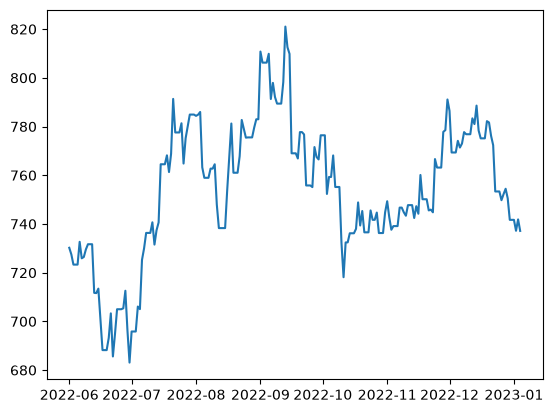

In [24]:
import matplotlib.pyplot as plt
plt.plot(filled_data["Close"])

<Figure size 1600x500 with 0 Axes>

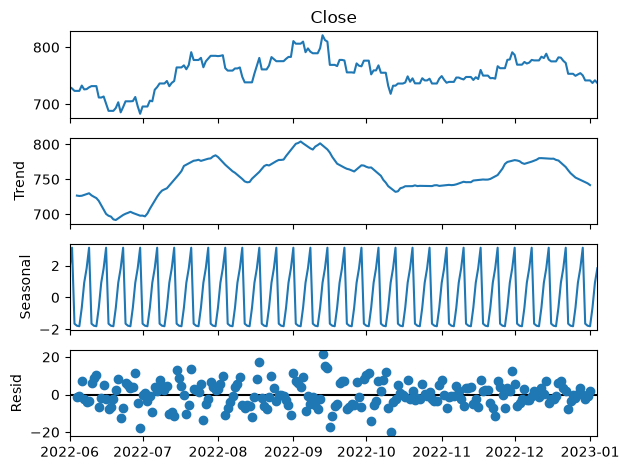

In [26]:
from matplotlib import pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

result=seasonal_decompose(filled_data["Close"], model='additive')
plt.figure(figsize=(16,5))
result.plot()
plt.show()

<Figure size 1600x500 with 0 Axes>

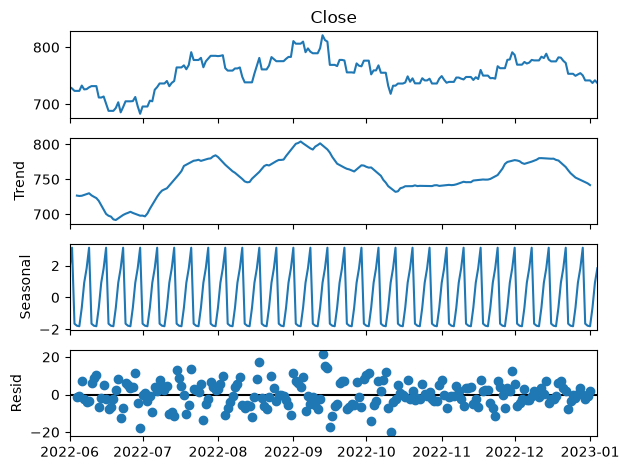

In [27]:
from pandas import read_csv
from matplotlib import pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(filled_data["Close"], model='additive')
plt.figure(figsize=(16,5))
result.plot()
plt.show()

In [28]:
# ADF Test
# Function to print out results in customised manner

from statsmodels.tsa.stattools import adfuller
def adf_test(timeseries,df,pollutant):
    plt.figure(figsize=(16,5))
    # Plot the data
    # ADF Test
    # Function to print out results in customised manner
    from statsmodels.tsa.stattools import adfuller
    print ('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print (dfoutput)
    ans=dfoutput
    print("Condition:")
    print("p-value<=0.05-->Accept Alternate Hypothesis")
    print("p-value>0.05-->Accept Null Hypothesis")
    if(ans['Test Statistic']<ans["Critical Value (1%)"] or ans['Test Statistic']<ans["Critical Value (5%)"] or ans['Test Statistic']<ans["Critical Value (10%)"] and ans["p-value"]<0.05):
        print("Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis")
        print("Reject null hypothesis:Non Stationarity")
        print("Accept Alternate hypothesis:Staionarity ")
        message="Stationarity based on ADH"
    else:
        print("Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis")
        print("Accept null hypothesis:Non Stationarity" )
        print("Reject Alternate hypothesis:Staionarity ")
        message="Non-stationarity based on ADH"
        
    plt.plot(df.index, df[pollutant], label = pollutant)
    plt.legend(loc='best')
    plt.title("{}_{}_2013 to 2021".format(message,pollutant))
    plt.savefig("{}_ADH.png".format(pollutant))
    plt.show()
    
    return message
    
# Call the function and run the test

Results of Dickey-Fuller Test:
Test Statistic                  -2.380664
p-value                          0.147268
#Lags Used                       0.000000
Number of Observations Used    217.000000
Critical Value (1%)             -3.460849
Critical Value (5%)             -2.874953
Critical Value (10%)            -2.573919
dtype: float64
Condition:
p-value<=0.05-->Accept Alternate Hypothesis
p-value>0.05-->Accept Null Hypothesis
Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis
Accept null hypothesis:Non Stationarity
Reject Alternate hypothesis:Staionarity 


/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_24619/3261369962.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag='AIC')


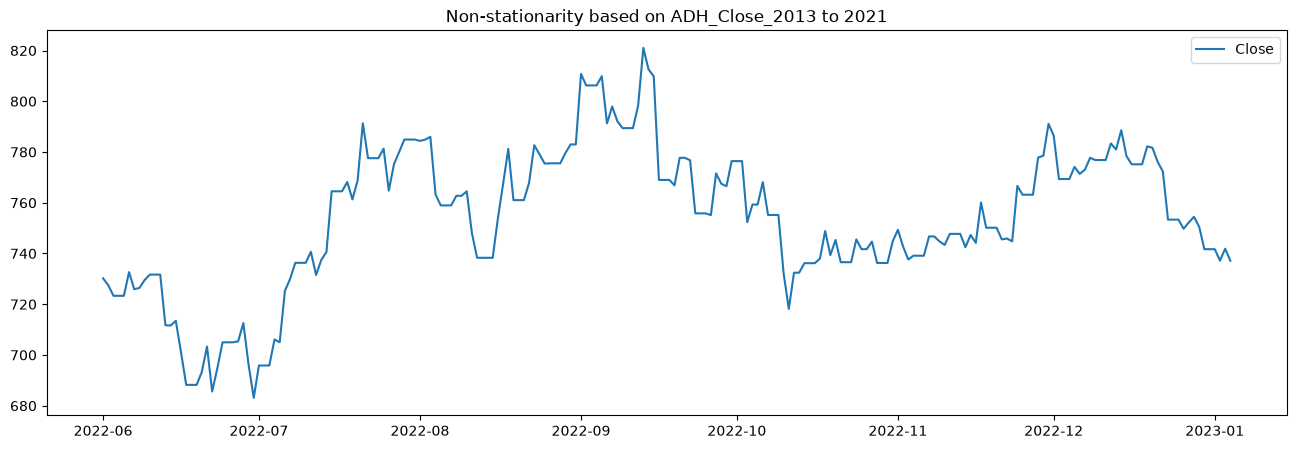

'Non-stationarity based on ADH'

In [30]:
adf_test(filled_data["Close"], filled_data, "Close")

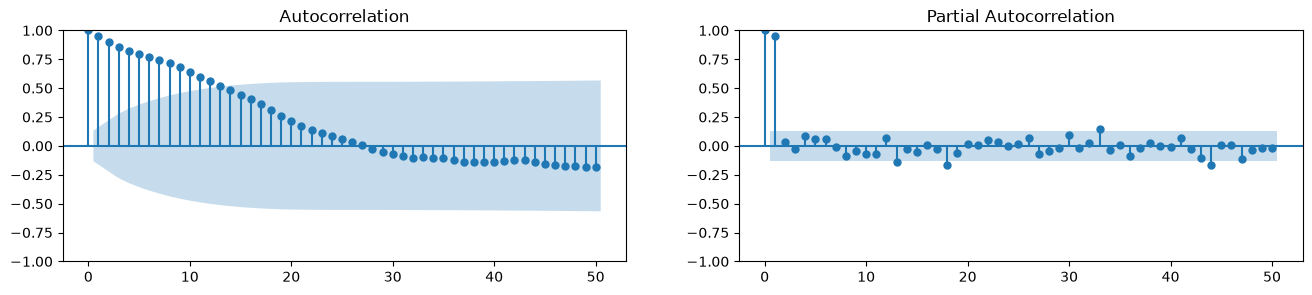

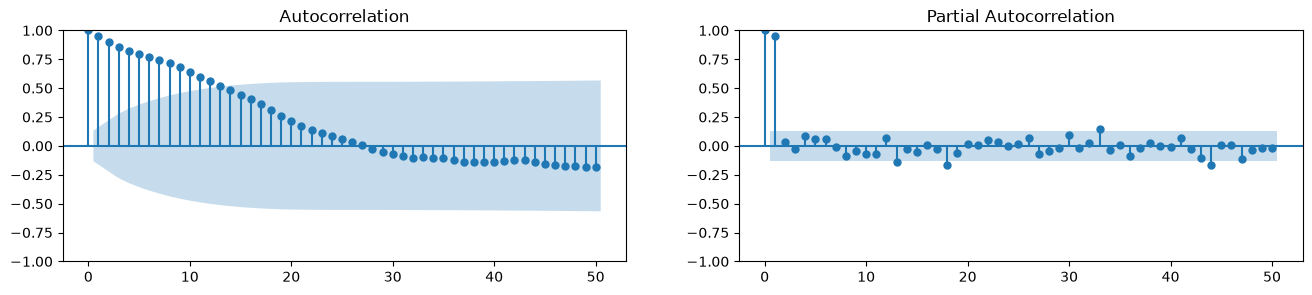

In [31]:
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(16,3), dpi= 100)
plot_acf(filled_data.Close.tolist(), lags=50, ax=axes[0])
plot_pacf(filled_data.Close.tolist(), lags=50, ax=axes[1])